In [ ]:
import pandas as pd
import numpy as np
import datetime
import seaborn as sns
import matplotlib.pyplot as plt

TopFly Knight

869487062829758

In [ ]:
path="C:'\Users'\Jose.Hurtado'\Downloads'\869487062829758.csv"
raw_data=pd.read_csv(str(path),sep=',')
raw_data.info()

SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 2-3: truncated \UXXXXXXXX escape (3342638875.py, line 1)

In [115]:
raw_data=pd.read_csv(r'C:\Users\Jose.Hurtado\Downloads\869487062829758.csv',sep=',')
raw_data.info()
print(raw_data.iloc[(raw_data.shape[0]-1),3],' -> ',raw_data.iloc[0,3])

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 29 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Row Id                     300 non-null    int64  
 1   Sequence #                 300 non-null    int64  
 2   Account Id                 300 non-null    int64  
 3   Server Time                300 non-null    str    
 4   Unit Time                  300 non-null    str    
 5   Latitude                   300 non-null    float64
 6   Longitude                  300 non-null    float64
 7   Driver Name                0 non-null      float64
 8   Event Name                 300 non-null    str    
 9   Raw Event                  300 non-null    str    
 10  GPS Speed                  300 non-null    float64
 11  ECU Speed                  0 non-null      float64
 12  Address                    300 non-null    str    
 13  Landmark ID                20 non-null     float64
 14  Satel

In [116]:
aux=pd.DataFrame()
aux=raw_data
aux['Headers']='NaN'

for i in range(0,aux.shape[0]):
    aux.iloc[i,29]=aux.iloc[i,28][0:8]

aux['Headers'].value_counts()

Headers
27270400    179
27270200    121
Name: count, dtype: int64

Odometer

In [117]:
unit_02=aux[aux['Raw Data'].str.contains('27270200')]
unit_04=aux[aux['Raw Data'].str.contains('27270400')]
unit_aux=pd.concat([unit_02,unit_04])
unit_aux['Odometer in meters']=0.0
odometer=[]
date=[]
raw=[]

for i in range(0,unit_aux.shape[0]):
    odometer.append(int(unit_aux.iloc[i,28][96:104],16))
    date.append(unit_aux.iloc[i,28][34:46])
    raw.append(unit_aux.iloc[i,28])

unit_aux['Odometer in meters']=odometer
unit_aux['Date']=date
unit_aux['Raw data']=raw

unit=unit_aux.sort_values('Date',ascending=True)

unit.info()

<class 'pandas.DataFrame'>
Index: 300 entries, 299 to 0
Data columns (total 33 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Row Id                     300 non-null    int64  
 1   Sequence #                 300 non-null    int64  
 2   Account Id                 300 non-null    int64  
 3   Server Time                300 non-null    str    
 4   Unit Time                  300 non-null    str    
 5   Latitude                   300 non-null    float64
 6   Longitude                  300 non-null    float64
 7   Driver Name                0 non-null      float64
 8   Event Name                 300 non-null    str    
 9   Raw Event                  300 non-null    str    
 10  GPS Speed                  300 non-null    float64
 11  ECU Speed                  0 non-null      float64
 12  Address                    300 non-null    str    
 13  Landmark ID                20 non-null     float64
 14  Satellites

261120142136 -> 0 -> 1475.0 -> 272704004901e808694870628297585616261120142136855b7f44800c99c289896040000000828090008040001dff41000005c31106040258000038400000000010f280000000ffd5
261120143155 -> 1 -> 1475.0 -> 272704004901e908694870628297585a17261120143155855b7f44800c99c289896040000000820008008090001eff41000005c31105600258000038400000000010f280000000ffd5
261120145036 -> 2 -> 1475.0 -> 272704004901ea08694870628297585816261120145036855b7f44800c99c289896040000000820008008090001eff41000005c31105640258000038400000000010f280000000ffd5
261120145705 -> 3 -> 1475.0 -> 272704004901eb0869487062829758d617261120145705855b7f44800c99c289896040000000820008008090001eff41000005c31100000258000038400000000010f280000000ff80
261120151841 -> 4 -> 1475.0 -> 272704004901ec08694870628297585216261120151841855b7f44800c99c289896040000000828008008090001eff41000005c31104440258000038400000000010f280000000ffd5
261120152901 -> 5 -> 1475.0 -> 2727020049184408694870628297585200261120152901855b7f44800c99c289896040000000820

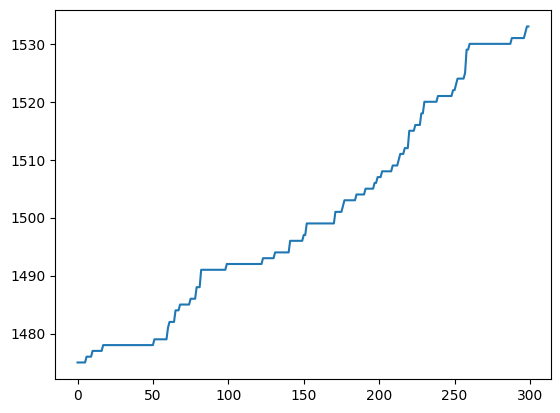

In [118]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,30]))
    x_axis.append(i)
    date.append(unit.iloc[i,31])
    raw_data_.append(unit.iloc[i,32])

#print("Delta odometer: ",y_axis[170]-y_axis[133],'meters')

for i in range(0,len(odometer)):
    print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

#print(odometer[len(odometer)-1]-odometer[0])
plt.plot(x_axis,y_axis)

Speed

In [119]:
speed=[]

for i in range(0,unit.shape[0]):
    speed.append(int(unit.iloc[i,32][70:74]))
    date.append(unit.iloc[i,28][34:46])
    raw.append(unit.iloc[i,28])
    #print(unit.iloc[i,32][70:74],int(unit.iloc[i,32][70:74]))

unit['Speed']=speed

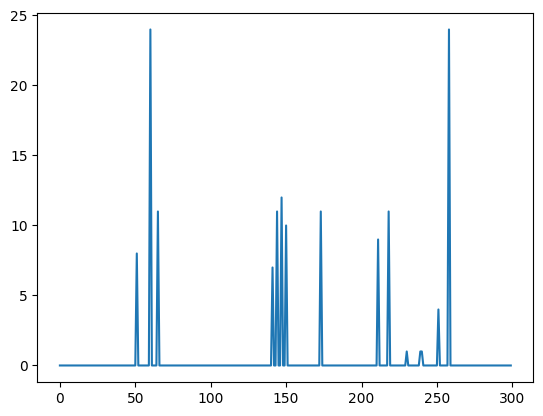

In [120]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append((float(unit.iloc[i,33]))/10)
    x_axis.append(i)
    date.append(unit.iloc[i,31])
    raw_data_.append(unit.iloc[i,32])
    #print(raw_data_[i])

for i in range(0,len(speed)):
    if (y_axis[i]>55):
        print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

plt.plot(x_axis,y_axis)

Battery

In [121]:
voltage=[]

for i in range(0,unit.shape[0]):
    voltage.append(int(unit.iloc[i,32][75:77],16))
    date.append(unit.iloc[i,28][34:46])
    raw.append(unit.iloc[i,28])
    #print(unit.iloc[i,32][70:74],int(unit.iloc[i,32][70:74]))

unit['Voltage']=voltage

unit.info()

<class 'pandas.DataFrame'>
Index: 300 entries, 299 to 0
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Row Id                     300 non-null    int64  
 1   Sequence #                 300 non-null    int64  
 2   Account Id                 300 non-null    int64  
 3   Server Time                300 non-null    str    
 4   Unit Time                  300 non-null    str    
 5   Latitude                   300 non-null    float64
 6   Longitude                  300 non-null    float64
 7   Driver Name                0 non-null      float64
 8   Event Name                 300 non-null    str    
 9   Raw Event                  300 non-null    str    
 10  GPS Speed                  300 non-null    float64
 11  ECU Speed                  0 non-null      float64
 12  Address                    300 non-null    str    
 13  Landmark ID                20 non-null     float64
 14  Satellites

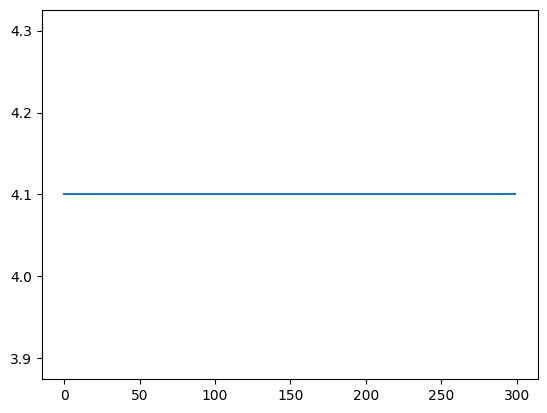

In [122]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,32][94:96])/10)
    x_axis.append(i)
    date.append(unit.iloc[i,31])
    raw_data_.append(unit.iloc[i,32])
    #print(raw_data_[i])

for i in range(0,len(voltage)):
    if (y_axis[i]>55):
        print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

plt.plot(x_axis,y_axis)

261120142136 -> 0 -> 100.0 -> 272704004901e808694870628297585616261120142136855b7f44800c99c289896040000000828090008040001dff41000005c31106040258000038400000000010f280000000ffd5
261120143155 -> 1 -> 100.0 -> 272704004901e908694870628297585a17261120143155855b7f44800c99c289896040000000820008008090001eff41000005c31105600258000038400000000010f280000000ffd5
261120145036 -> 2 -> 100.0 -> 272704004901ea08694870628297585816261120145036855b7f44800c99c289896040000000820008008090001eff41000005c31105640258000038400000000010f280000000ffd5
261120145705 -> 3 -> 100.0 -> 272704004901eb0869487062829758d617261120145705855b7f44800c99c289896040000000820008008090001eff41000005c31100000258000038400000000010f280000000ff80
261120151841 -> 4 -> 100.0 -> 272704004901ec08694870628297585216261120151841855b7f44800c99c289896040000000828008008090001eff41000005c31104440258000038400000000010f280000000ffd5
261120152901 -> 5 -> 100.0 -> 2727020049184408694870628297585200261120152901855b7f44800c99c289896040000000820140048

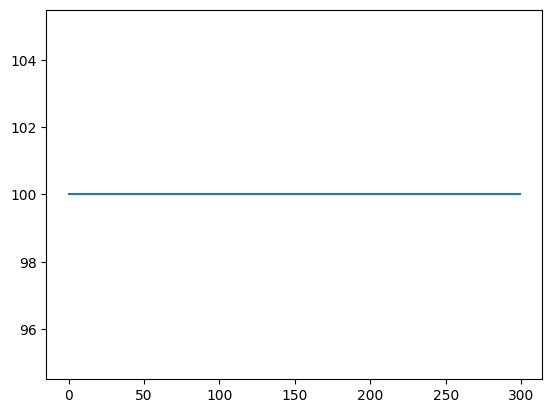

In [123]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,27]))
    x_axis.append(i)
    date.append(unit.iloc[i,31])
    raw_data_.append(unit.iloc[i,32])
    #print(raw_data_[i])

for i in range(0,len(voltage)):
    if (y_axis[i]>55):
        print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

plt.plot(x_axis,y_axis)

Panic

In [124]:
for i in range(0,unit.shape[0]):
    #print(unit.iloc[i,32][32:34])
    if (unit.iloc[i,32][32:34]=='03'):
        print('Panic',unit.iloc[i,31])

Panic 261123181113
Panic 261123181250
Panic 261123181445
Panic 261123181605
Panic 261123181745


Motion

In [125]:
date=[]
raw_data_=[]

for i in range(0,raw_data.shape[0]):
    if (raw_data.iloc[i,8]=='Motion'):
        print(raw_data.iloc[i,8],raw_data.iloc[i,28][34:46],raw_data.iloc[i,3],raw_data.iloc[i,28])

Motion 261125122941 2026/11/25 07:29:43 272702004918bd0869487062829758520026112512294162787b44260b99c28f7a6040000000408008100020001fff41000005fbb503e40258000038400000000010f280000000ffd5
Motion 261125121942 2026/11/25 07:19:43 272702004918bc0869487062829758d00026112512194262787b44260b99c28f7a6040000000400008098040001fff41000005fbb500040258000038400000000010f280000000ff80
Motion 261125120942 2026/11/25 07:09:43 272702004918bb0869487062829758530026112512094262787b44260b99c28f7a6040000000400008088030001fff41000005fbb503e40258000038400000000010f280000000ffd5
Motion 261125115941 2026/11/25 06:59:43 272702004918ba0869487062829758540026112511594162787b44260b99c28f7a6040000000400008098040001fff41000005fbb503a40258000038400000000010f280000000ffd5
Motion 261125114942 2026/11/25 06:49:43 272702004918b90869487062829758530026112511494262787b44260b99c28f7a6040000000400018098040001eff41000005fbb504140258000038400000000010f280000000ffd5
Motion 261125113941 2026/11/25 06:39:42 272702004918b808694870628